In [ ]:
!pip install -q prophet chronos-forecasting

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, logging
from IPython.display import display, Markdown
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

NARANJA, OSCURO, GRIS, AZUL, ROJO, VERDE = "#FF871E", "#262626", "#8A8A8A", "#2E86AB", "#C0392B", "#6BAA75"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
SEED = 2026
rng = np.random.default_rng(SEED)
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
print("Entorno listo.")

Entorno listo.


In [ ]:
import os
ARCHIVO = "monthly_full_release_long_format.csv"
if not os.path.exists(ARCHIVO):
    raise FileNotFoundError(f"No se encontró '{ARCHIVO}'. Súbalo al panel de archivos de Colab (carpeta /content) y vuelva a correr esta celda.")
cols = ["Area", "Date", "Variable", "Unit", "Value"]
crudo = pd.read_csv(ARCHIVO, usecols=cols, parse_dates=["Date"])
print("Filas del archivo:", len(crudo))
cr = crudo[(crudo["Area"] == "Costa Rica") & (crudo["Unit"] == "TWh")]
cr = (cr.pivot_table(index="Date", columns="Variable", values="Value")
      * 1000).asfreq("MS")[:"2026-06"]          # GWh, corte fijo
hidro = cr["Hydro"].rename("hidro")
fosil = cr["Fossil"].rename("fosil")
print(hidro.shape)
assert hidro.shape == (90,) and not hidro.isna().any(), "Revisar la descarga"
hidro.tail()

Filas del archivo: 111218
(90,)


,hidro
Date,
2026-02-01,740.0
2026-03-01,660.0
2026-04-01,690.0
2026-05-01,830.0
2026-06-01,840.0


In [ ]:
# Partición y métricas (las mismas para todos los modelos)
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
def mae(a, b):  return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def mase(real, pron, entrenamiento, m=12):
    entrenamiento = np.asarray(entrenamiento)
    escala = np.mean(np.abs(entrenamiento[m:] - entrenamiento[:-m]))
    return float(np.mean(np.abs(np.asarray(real) - np.asarray(pron))) / escala)

train, test = hidro[:"2025-06"], hidro["2025-07":]
h = len(test)
assert len(train) == 78 and h == 12
print(f"Entrenamiento: {train.index.min():%Y-%m} a {train.index.max():%Y-%m} ({len(train)} meses)")
print(f"Prueba:        {test.index.min():%Y-%m} a {test.index.max():%Y-%m} ({h} meses)")
print(f"Escala del MASE (MAE del ingenuo estacional en train): {np.mean(np.abs(train.values[12:] - train.values[:-12])):.1f} GWh")

Entrenamiento: 2019-01 a 2025-06 (78 meses)
Prueba:        2025-07 a 2026-06 (12 meses)
Escala del MASE (MAE del ingenuo estacional en train): 87.6 GWh


PARTE 1
-

### 1.a. Exploración

**(I) Gráficos de la serie hidroeléctrica y de la generación fósil.**

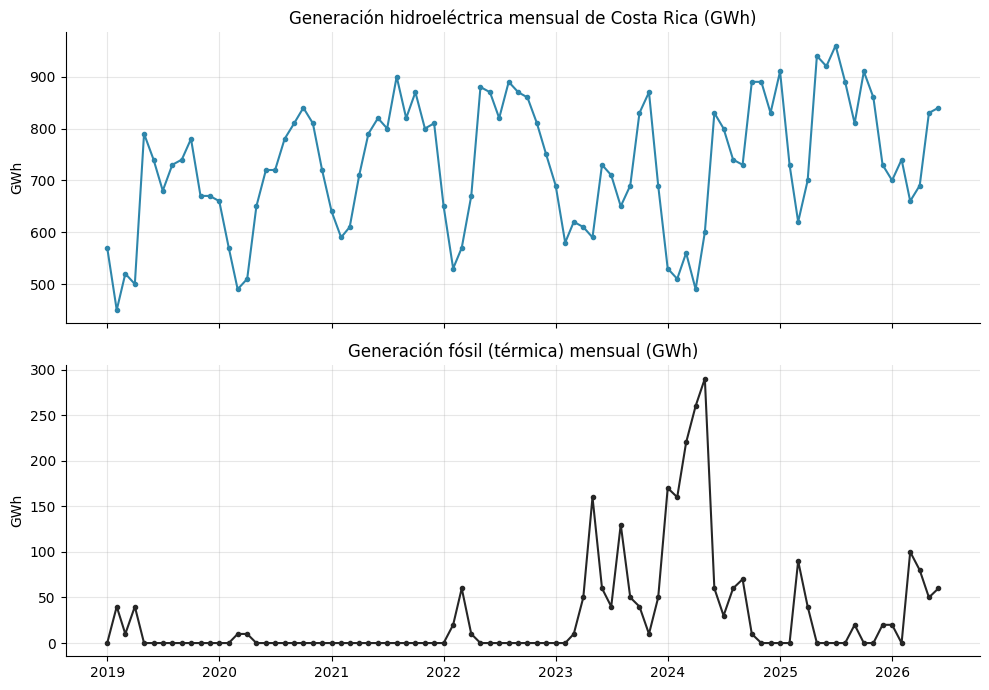

Totales por año (GWh; 2026 solo tiene enero a junio):
       hidro   fosil
Date                
2019  7840.0    90.0
2020  8280.0    20.0
2021  9160.0     0.0
2022  9170.0    90.0
2023  8260.0   600.0
2024  8400.0  1330.0
2025  9980.0   170.0
2026  4460.0   310.0


In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axs[0].plot(hidro.index, hidro, color=AZUL, marker="o", ms=3)
axs[0].set_title("Generación hidroeléctrica mensual de Costa Rica (GWh)"); axs[0].set_ylabel("GWh"); axs[0].grid(alpha=.3)
axs[1].plot(fosil.index, fosil, color=OSCURO, marker="o", ms=3)
axs[1].set_title("Generación fósil (térmica) mensual (GWh)"); axs[1].set_ylabel("GWh"); axs[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

anual = pd.DataFrame({"hidro": hidro.groupby(hidro.index.year).sum(),
                      "fosil": fosil.groupby(fosil.index.year).sum()}).round(0)
print("Totales por año (GWh; 2026 solo tiene enero a junio):")
print(anual)

**(II) Tendencia y estacionalidad.** Perfil promedio por mes del año:

      mean    min    max
ene  668.8  530.0  910.0
feb  587.5  450.0  740.0
mar  581.2  490.0  660.0
abr  610.0  490.0  710.0
may  758.8  590.0  940.0
jun  808.8  720.0  920.0
jul  784.3  680.0  960.0
ago  797.1  650.0  900.0
sep  781.4  690.0  870.0
oct  854.3  780.0  910.0
nov  815.7  670.0  890.0
dic  742.9  670.0  830.0


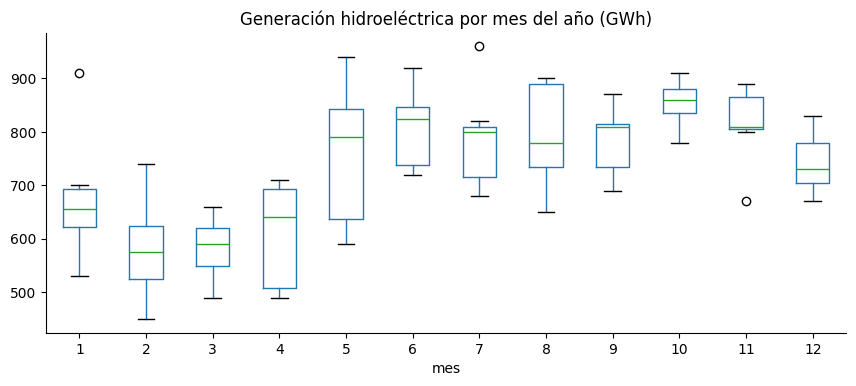

**Lectura automática de la tabla:** los meses que más generan en promedio son **oct, nov, jun** y los que menos son **mar, feb, abr**. La pendiente lineal de toda la serie es de **1.57 GWh por mes** (≈ 19 GWh por año), pequeña frente al nivel mensual de 728 GWh.

In [ ]:
perfil = hidro.groupby(hidro.index.month).agg(["mean", "min", "max"]).round(1)
perfil.index = MESES
print(perfil)

fig, ax = plt.subplots()
hidro.to_frame().assign(mes=hidro.index.month).boxplot(column="hidro", by="mes", grid=False, ax=ax)
plt.suptitle(""); ax.set_title("Generación hidroeléctrica por mes del año (GWh)"); ax.set_xlabel("mes"); plt.show()

orden = hidro.groupby(hidro.index.month).mean().sort_values()
mas = [MESES[m - 1] for m in orden.index[-3:][::-1]]
menos = [MESES[m - 1] for m in orden.index[:3]]
pend = np.polyfit(np.arange(len(hidro)), hidro.values, 1)[0]
display(Markdown(f"**Lectura automática de la tabla:** los meses que más generan en promedio son **{', '.join(mas)}** "
                 f"y los que menos son **{', '.join(menos)}**. La pendiente lineal de toda la serie es de **{pend:.2f} GWh por mes** "
                 f"(≈ {pend*12:.0f} GWh por año), pequeña frente al nivel mensual de {hidro.mean():.0f} GWh."))

La serie no muestra una tendencia clara: la pendiente lineal es de apenas 1.57 GWh por mes (≈ 19 GWh por año), muy pequeña frente al nivel promedio de 728 GWh mensuales, así que lo que domina es el patrón anual. Los meses que más generan en promedio son octubre (854 GWh), noviembre (816) y junio (809), y los que menos son marzo (581), febrero (588) y abril (610). De mayo a noviembre la generación se mantiene alta (promedios de 758 a 854 GWh) y de febrero a abril cae a su nivel más bajo. Esto coincide con la época lluviosa (aprox. mayo a noviembre), cuando ríos y embalses están llenos, y con la época seca (aprox. diciembre a abril), cuando el caudal baja; justo en la época seca la demanda es alta, por lo que ahí se necesita más respaldo térmico. La dispersión es mayor en los meses de transición (mayo va de 590 a 940 GWh), porque depende de cuándo empiece la lluvia cada año.

**(III) Descomposición y qué pasó en 2023 y 2024.**

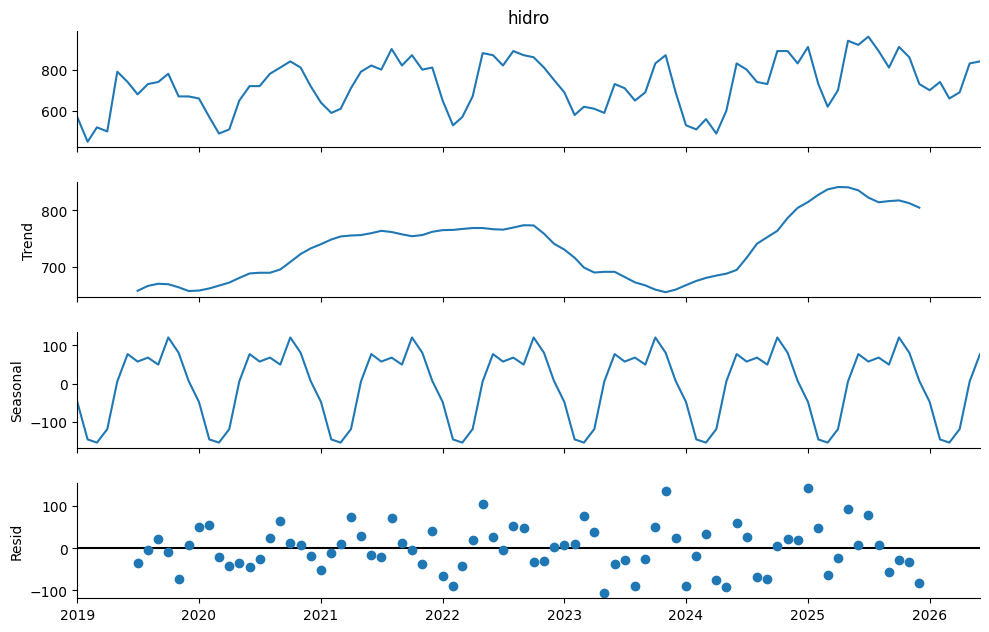

      hidro_total  fosil_total  hidro_media  fosil_media
Date                                                    
2019       7840.0         90.0        653.3          7.5
2020       8280.0         20.0        690.0          1.7
2021       9160.0          0.0        763.3          0.0
2022       9170.0         90.0        764.2          7.5
2023       8260.0        600.0        688.3         50.0
2024       8400.0       1330.0        700.0        110.8
2025       9980.0        170.0        831.7         14.2
2026       4460.0        310.0        743.3         51.7

Efecto estacional (GWh sobre la tendencia):
ene    -47.8
feb   -145.8
mar   -154.1
abr   -118.8
may      5.6
jun     77.2
jul     57.6
ago     68.0
sep     49.7
oct    120.6
nov     80.7
dic      7.0
Name: seasonal, dtype: float64

Residuos más negativos (meses peores de lo que predice tendencia + estacionalidad):
Date
2023-05-01   -106.5
2024-05-01    -93.1
2023-08-01    -90.1
2022-02-01    -89.6
2024-01-01    -89.3
Name: re

In [ ]:
desc = seasonal_decompose(hidro, model="additive", period=12)
fig = desc.plot(); fig.set_size_inches(10, 7); plt.show()

# Comparación hidro vs fósil por año completo y en el periodo seco 2024 (ene-jun)
comp = pd.DataFrame({"hidro_total": hidro.groupby(hidro.index.year).sum(),
                     "fosil_total": fosil.groupby(fosil.index.year).sum(),
                     "hidro_media": hidro.groupby(hidro.index.year).mean(),
                     "fosil_media": fosil.groupby(fosil.index.year).mean()}).round(1)
print(comp)
print("\nEfecto estacional (GWh sobre la tendencia):")
print(desc.seasonal.iloc[:12].round(1).set_axis(MESES))
print("\nResiduos más negativos (meses peores de lo que predice tendencia + estacionalidad):")
print(desc.resid.dropna().nsmallest(5).round(1))

 La descomposición separa una tendencia, un patrón estacional idéntico cada año (alto de mayo a noviembre, con máximo en octubre de +121 GWh; bajo de febrero a abril, con mínimo en marzo de −154 GWh) y un residuo. La tendencia sube de 2019 a 2022 (de ~660 a ~770 GWh), baja durante 2023 hasta un mínimo cerca de 655 GWh a inicios de 2024 y luego se recupera hasta ~840 GWh en 2025; esa caída no la explica la estacionalidad.

2023 y 2024. La hidro anual pasó de 9 170 GWh en 2022 a 8 260 GWh en 2023 (−910 GWh, cerca de −10 %), y los residuos más negativos caen en esos años: mayo de 2023 (−106.5), mayo de 2024 (−93.1), agosto de 2023 (−90.1) y enero de 2024 (−89.3). Que dos sean mayo, cuando normalmente empiezan las lluvias, es consistente con un inicio tardío o débil de la época lluviosa durante El Niño. En el gráfico y la tabla de generación fósil se ve la respuesta: pasó de 90 GWh en 2022 a 600 GWh en 2023 y 1 330 GWh en 2024, tras años casi sin térmicas (0 GWh en 2021). Como la demanda no baja, el país cubrió con térmicas lo que la hidro dejó de aportar. En 2025 la hidro se recupera (9 980 GWh) y la generación fósil vuelve a 170 GWh.

### 1.b. Un modelo clásico

**(I) Configuración y justificación.** Probamos dos clásicos de statsmodels:

**Holt-Winters.** Usamos estacionalidad aditiva (la amplitud del patrón anual no crece con el nivel). Para decidir la tendencia comparamos AICc: 686.1 con tendencia y 680.3 sin tendencia; como menor es mejor, **no usamos tendencia**. Coincide con la exploración: la pendiente lineal es de solo 1.57 GWh por mes y la tendencia de la descomposición sube y baja en vez de crecer de forma sostenida.

**SARIMA(1,0,0)(0,1,1)₁₂ sin constante.** La diferencia estacional (D = 1) elimina el patrón anual; no incluimos constante porque no hay deriva clara; el AR(1) recoge la memoria de un mes al siguiente y el MA estacional corrige con el error del mismo mes del año anterior. Ambos coeficientes son significativos (ar.L1 = 0.666, p < 0.001; ma.S.L12 = −0.815, p = 0.003).

In [ ]:
hw_con = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit()
hw_sin = ExponentialSmoothing(train, trend=None, seasonal="add", seasonal_periods=12).fit()
print(f"AICc con tendencia:  {hw_con.aicc:.1f}")
print(f"AICc sin tendencia:  {hw_sin.aicc:.1f}")
TENDENCIA_HW = "add" if hw_con.aicc < hw_sin.aicc else None
print("Tendencia elegida para Holt-Winters:", TENDENCIA_HW)
hw = hw_con if TENDENCIA_HW == "add" else hw_sin

sarima = SARIMAX(train, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sarima.summary().tables[1])

AICc con tendencia:  686.1
AICc sin tendencia:  680.3
Tendencia elegida para Holt-Winters: None
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6657      0.117      5.699      0.000       0.437       0.895
ma.S.L12      -0.8154      0.278     -2.936      0.003      -1.360      -0.271
sigma2      5059.0918   1298.813      3.895      0.000    2513.465    7604.719


**(II) Pronóstico de los 12 meses de prueba, métricas y gráfico.**

                RMSE     MAE   MASE
Holt-Winters  79.740  72.497  0.828
SARIMA        73.794  59.320  0.677


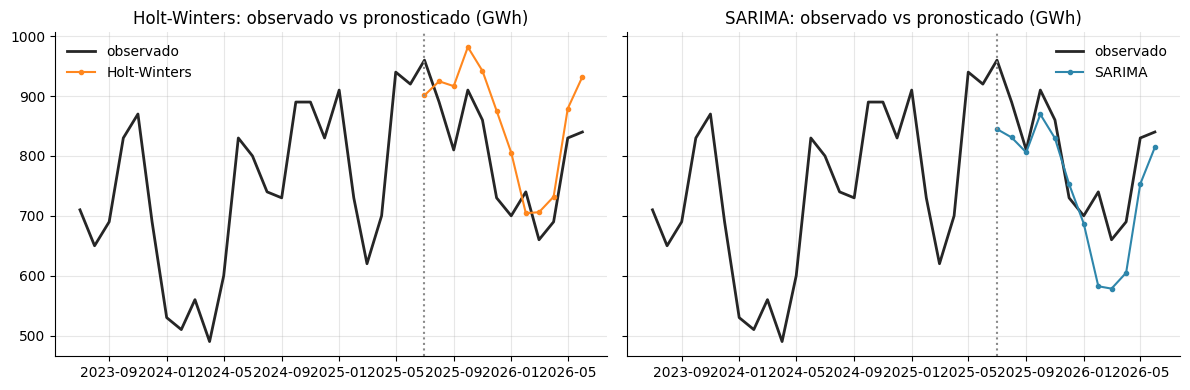

In [ ]:
pron = {"Ingenuo estacional": train.values[-12:],
        "Holt-Winters": hw.forecast(h).values,
        "SARIMA": sarima.forecast(h).values}

def tabla_metricas(pron, real=test, entren=train):
    return pd.DataFrame({n: {"RMSE": rmse(real, f), "MAE": mae(real, f), "MASE": mase(real, f, entren.values)}
                         for n, f in pron.items()}).T

print(tabla_metricas({k: v for k, v in pron.items() if k != "Ingenuo estacional"}).round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, nombre, c in zip(axs, ["Holt-Winters", "SARIMA"], [NARANJA, AZUL]):
    ax.plot(hidro["2023-07":].index, hidro["2023-07":], color=OSCURO, lw=2, label="observado")
    ax.plot(test.index, pron[nombre], color=c, marker="o", ms=3, label=nombre)
    ax.axvline(test.index[0], color=GRIS, ls=":"); ax.set_title(f"{nombre}: observado vs pronosticado (GWh)")
    ax.legend(frameon=False); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 1.c. Un modelo moderno


**(I)** Usamos **Chronos-2** (modelo fundacional, *zero-shot*: no se entrena con nuestros datos, solo recibe el historial como contexto) y también **Prophet** (tendencia + estacionalidad anual) como segundo moderno. Ambos reciben solo el entrenamiento.

In [ ]:
from prophet import Prophet
from chronos import Chronos2Pipeline

def df_ds(s):  return pd.DataFrame({"ds": s.index, "y": s.values})
def df_ctx(s): return pd.DataFrame({"id": "CR", "timestamp": s.index, "target": s.values})

def prophet_modelo(s):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(df_ds(s))
    return m

chronos = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")

def chronos_cuantiles(s, h, niveles):
    out = chronos.predict_df(df_ctx(s), prediction_length=h, quantile_levels=list(niveles),
                             id_column="id", timestamp_column="timestamp", target="target")
    return out

m_prophet = prophet_modelo(train)
fc_p = m_prophet.predict(m_prophet.make_future_dataframe(periods=h, freq="MS"))
pron["Prophet"] = fc_p["yhat"].values[-h:]
pron["Chronos-2"] = chronos_cuantiles(train, h, [0.1, 0.5, 0.9])["0.5"].values
print("Pronósticos listos:", list(pron))

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Pronósticos listos: ['Ingenuo estacional', 'Holt-Winters', 'SARIMA', 'Prophet', 'Chronos-2']


**(II) Métricas y gráfico de los modernos.**

             RMSE     MAE   MASE
Prophet    58.429  41.930  0.479
Chronos-2  73.429  61.918  0.707


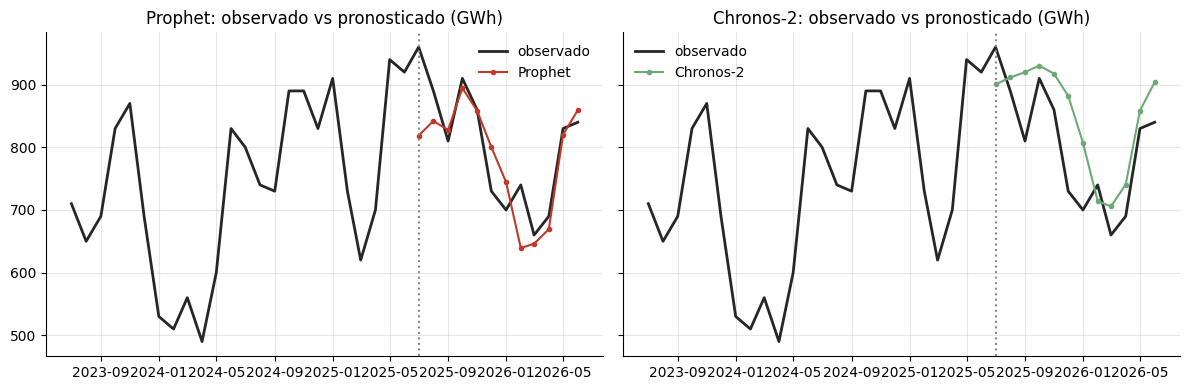

In [ ]:
print(tabla_metricas({k: pron[k] for k in ["Prophet", "Chronos-2"]}).round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, nombre, c in zip(axs, ["Prophet", "Chronos-2"], [ROJO, VERDE]):
    ax.plot(hidro["2023-07":].index, hidro["2023-07":], color=OSCURO, lw=2, label="observado")
    ax.plot(test.index, pron[nombre], color=c, marker="o", ms=3, label=nombre)
    ax.axvline(test.index[0], color=GRIS, ls=":"); ax.set_title(f"{nombre}: observado vs pronosticado (GWh)")
    ax.legend(frameon=False); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 1.d. Comparación y validación

**(I) Tabla con los cinco pronósticos sobre la misma prueba (jul 2025 a jun 2026).**

                       RMSE     MAE   MASE
Prophet              58.429  41.930  0.479
SARIMA               73.794  59.320  0.677
Chronos-2            73.429  61.918  0.707
Holt-Winters         79.740  72.497  0.828
Ingenuo estacional  104.163  83.333  0.952


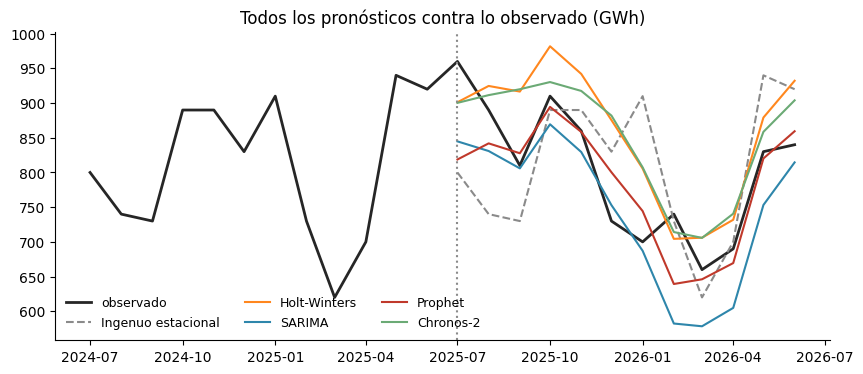

In [ ]:
tab1 = tabla_metricas(pron).sort_values("MASE")
print(tab1.round(3))

fig, ax = plt.subplots()
ax.plot(hidro["2024-07":].index, hidro["2024-07":], color=OSCURO, lw=2, label="observado")
for (n, f), c in zip(pron.items(), [GRIS, NARANJA, AZUL, ROJO, VERDE]):
    ax.plot(test.index, f, color=c, ls="--" if n.startswith("Ingenuo") else "-", label=n)
ax.axvline(test.index[0], color=GRIS, ls=":"); ax.legend(ncol=3, fontsize=9, frameon=False)
ax.set_title("Todos los pronósticos contra lo observado (GWh)"); plt.show()

**(II) Ventana expansiva.** Tres inicios de prueba (jul 2023, jul 2024, jul 2025). En cada uno se entrena con **todo lo anterior** y se pronostican 12 meses; el MASE se escala con el ingenuo estacional del entrenamiento de esa misma ventana.

MASE por ventana (m = 12):
prueba desde        2023-07  2024-07  2025-07  promedio  peor ventana
modelo                                                               
SARIMA                1.121    1.555    0.677     1.118         1.555
Chronos-2             1.076    1.625    0.707     1.136         1.625
Holt-Winters          0.993    1.894    0.828     1.238         1.894
Prophet               1.542    2.332    0.479     1.451         2.332
Ingenuo estacional    1.479    1.938    0.952     1.456         1.938


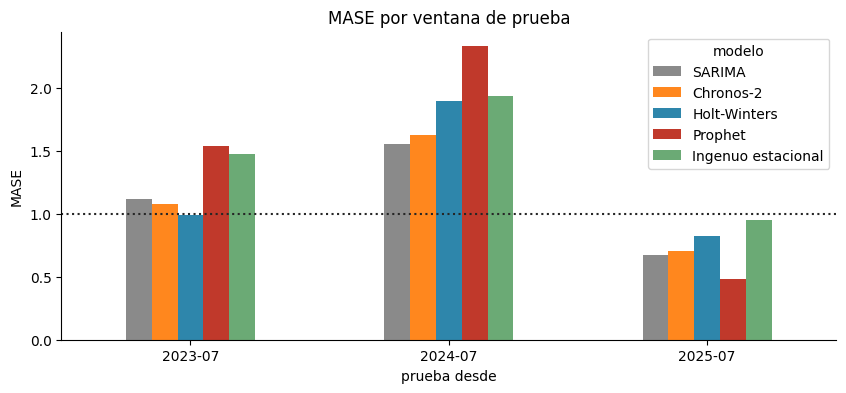

In [ ]:
def pronosticar(tr, h=12):
    out = {"Ingenuo estacional": tr.values[-12:]}
    out["Holt-Winters"] = ExponentialSmoothing(tr, trend=TENDENCIA_HW, seasonal="add",
                                               seasonal_periods=12).fit().forecast(h).values
    out["SARIMA"] = SARIMAX(tr, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(h).values
    mp = prophet_modelo(tr)
    out["Prophet"] = mp.predict(mp.make_future_dataframe(periods=h, freq="MS"))["yhat"].values[-h:]
    out["Chronos-2"] = chronos_cuantiles(tr, h, [0.5])["0.5"].values
    return out

INICIOS = ["2023-07", "2024-07", "2025-07"]
filas, mae_filas = [], []
for inicio in INICIOS:
    tr = hidro[hidro.index < inicio]
    te = hidro[inicio:].iloc[:12]
    for nombre, f in pronosticar(tr).items():
        filas.append({"prueba desde": inicio, "modelo": nombre, "MASE": mase(te, f, tr.values)})
cv_ts = pd.DataFrame(filas).pivot(index="modelo", columns="prueba desde", values="MASE")[INICIOS]
cv_ts["promedio"] = cv_ts.mean(axis=1)
cv_ts["peor ventana"] = cv_ts[INICIOS].max(axis=1)
cv_ts = cv_ts.sort_values("promedio")
print("MASE por ventana (m = 12):")
print(cv_ts.round(3))

cv_ts[INICIOS].T.plot(kind="bar", figsize=(10, 4), rot=0, color=[GRIS, NARANJA, AZUL, ROJO, VERDE][:len(cv_ts)])
plt.axhline(1, color=OSCURO, ls=":"); plt.title("MASE por ventana de prueba"); plt.ylabel("MASE"); plt.show()

**(III) Elección del mejor modelo con un criterio explícito.**

In [ ]:
candidatos = cv_ts.drop(index="Ingenuo estacional")
MEJOR = candidatos["promedio"].idxmin()                      # criterio: menor MASE promedio
estable = (candidatos["peor ventana"] <= candidatos["peor ventana"].min() * 1.25)   # y peor ventana no muy lejos de la mejor
print("Criterio: menor MASE promedio entre las 3 ventanas; se revisa que su peor ventana sea razonable.")
print("Modelo elegido:", MEJOR)
print(f"  MASE promedio = {cv_ts.loc[MEJOR,'promedio']:.3f} | peor ventana = {cv_ts.loc[MEJOR,'peor ventana']:.3f} "
      f"| ingenuo promedio = {cv_ts.loc['Ingenuo estacional','promedio']:.3f}")
print("¿Su peor ventana está a menos de 25 % de la mejor peor ventana?:", bool(estable[MEJOR]))

V24 = "2023-07"   # la ventana que contiene el 2024 (jul 2023 a jun 2024)
lineas = [f"* **{n}**: MASE en la ventana que incluye 2024 = {cv_ts.loc[n, V24]:.2f}; "
          f"promedio de las otras dos = {cv_ts.loc[n, [i for i in INICIOS if i != V24]].mean():.2f}."
          for n in cv_ts.index]
display(Markdown("**Qué pasó con cada modelo en la ventana que incluye 2024 (jul 2023 a jun 2024):**\n\n" + "\n".join(lineas)))

Criterio: menor MASE promedio entre las 3 ventanas; se revisa que su peor ventana sea razonable.
Modelo elegido: SARIMA
  MASE promedio = 1.118 | peor ventana = 1.555 | ingenuo promedio = 1.456
¿Su peor ventana está a menos de 25 % de la mejor peor ventana?: True


**Qué pasó con cada modelo en la ventana que incluye 2024 (jul 2023 a jun 2024):**

* **SARIMA**: MASE en la ventana que incluye 2024 = 1.12; promedio de las otras dos = 1.12.
* **Chronos-2**: MASE en la ventana que incluye 2024 = 1.08; promedio de las otras dos = 1.17.
* **Holt-Winters**: MASE en la ventana que incluye 2024 = 0.99; promedio de las otras dos = 1.36.
* **Prophet**: MASE en la ventana que incluye 2024 = 1.54; promedio de las otras dos = 1.41.
* **Ingenuo estacional**: MASE en la ventana que incluye 2024 = 1.48; promedio de las otras dos = 1.44.

Elegimos SARIMA(1,0,0)(0,1,1)₁₂ con el criterio de menor MASE promedio en las tres ventanas expansivas: 1.118, frente a 1.136 de Chronos-2, 1.238 de Holt-Winters, 1.451 de Prophet y 1.456 del ingenuo estacional. También tiene la mejor “peor ventana” (1.555, contra 1.625, 1.894 y 2.332 de los demás) y le gana al ingenuo en las tres ventanas (1.121 vs 1.479, 1.555 vs 1.938 y 0.677 vs 0.952), es decir, comete cerca de 23 % menos error que el ingenuo en promedio. Prophet fue el mejor con un solo año de prueba (MASE 0.479), pero pierde contra el ingenuo en dos de las tres ventanas, lo que muestra que un solo año de prueba engaña. La ventaja de SARIMA sobre Chronos-2 es pequeña (1.118 vs 1.136), casi un empate; nos quedamos con SARIMA por el criterio y porque es más simple y más interpretable (tres parámetros). Que el MASE de varias ventanas sea mayor que 1 no significa que el modelo sea malo: el ingenuo también supera 1 en dos ventanas, porque son años más difíciles (El Niño) que el entrenamiento.

### 1.e. Pronóstico final y riesgo

**(I)** Reentrenamos el modelo elegido con **toda** la serie (ene 2019 a jun 2026) y pronosticamos jul 2026 a jun 2027. La banda del 80 % sale de **5000 trayectorias simuladas** del propio modelo (percentiles 10 y 90 de cada mes).

Modelo final: SARIMA | trayectorias simuladas: 5000


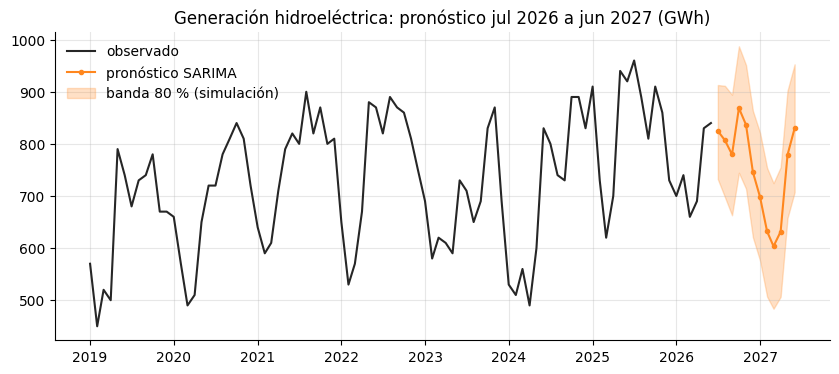

In [ ]:
NSIM = 5000
FUTURO = pd.date_range("2026-07-01", periods=12, freq="MS")

def simular_con_semilla(simular, h, **kw):
    "statsmodels cambió el argumento de la semilla (random_state -> rng); esto funciona en ambas versiones."
    try:
        return simular(h, rng=np.random.default_rng(SEED), **kw)
    except TypeError:
        return simular(h, random_state=SEED, **kw)

def pronostico_y_simulaciones(nombre, s, h=12, n=NSIM):
    "Devuelve (pronóstico puntual de h meses, matriz h x n de trayectorias simuladas)."
    if nombre == "Holt-Winters":
        m = ExponentialSmoothing(s, trend=TENDENCIA_HW, seasonal="add", seasonal_periods=12).fit()
        sims = np.asarray(simular_con_semilla(m.simulate, h, repetitions=n, anchor="end", error="add"))
        return m.forecast(h).values, sims
    if nombre == "SARIMA":
        m = SARIMAX(s, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
        sims = np.asarray(simular_con_semilla(m.simulate, h, repetitions=n, anchor="end")).reshape(h, n)
        return m.forecast(h).values, sims
    if nombre == "Prophet":
        m = prophet_modelo(s)
        fut = m.make_future_dataframe(periods=h, freq="MS")
        sims = np.asarray(m.predictive_samples(fut)["yhat"])[-h:, :]
        return m.predict(fut)["yhat"].values[-h:], sims
    if nombre == "Chronos-2":
        niveles = np.round(np.arange(0.05, 0.96, 0.05), 2)
        q = chronos_cuantiles(s, h, niveles)
        Q = np.column_stack([q[str(float(l))].values for l in niveles])       # h x niveles
        u = rng.uniform(niveles[0], niveles[-1], size=(h, n))
        sims = np.vstack([np.interp(u[i], niveles, Q[i]) for i in range(h)])  # muestreo por CDF inversa
        return Q[:, 9], sims   # columna 9 = cuantil 0.5
    raise ValueError(nombre)

media, sims = pronostico_y_simulaciones(MEJOR, hidro)
p10, p90 = np.percentile(sims, 10, axis=1), np.percentile(sims, 90, axis=1)
print("Modelo final:", MEJOR, "| trayectorias simuladas:", sims.shape[1])

fig, ax = plt.subplots()
ax.plot(hidro.index, hidro, color=OSCURO, label="observado")
ax.plot(FUTURO, media, color=NARANJA, marker="o", ms=3, label=f"pronóstico {MEJOR}")
ax.fill_between(FUTURO, p10, p90, color=NARANJA, alpha=.25, label="banda 80 % (simulación)")
ax.set_title("Generación hidroeléctrica: pronóstico jul 2026 a jun 2027 (GWh)"); ax.legend(frameon=False); ax.grid(alpha=.3)
plt.show()

**(II) Archivo `predicciones_hidro.csv`** con columnas `mes`, `pronostico`, `p10`, `p90`.

In [ ]:
salida = pd.DataFrame({"mes": FUTURO.strftime("%Y-%m"), "pronostico": np.round(media, 1),
                       "p10": np.round(p10, 1), "p90": np.round(p90, 1)})
salida.to_csv("predicciones_hidro.csv", index=False)
print(pd.read_csv("predicciones_hidro.csv").to_string(index=False))
assert list(salida.columns) == ["mes", "pronostico", "p10", "p90"] and len(salida) == 12

    mes  pronostico   p10   p90
2026-07       824.9 732.3 912.9
2026-08       806.8 697.9 911.4
2026-09       779.7 663.0 894.3
2026-10       868.7 744.6 987.3
2026-11       836.7 714.0 951.3
2026-12       745.9 620.8 863.5
2027-01       698.3 576.3 821.6
2027-02       631.9 506.9 753.9
2027-03       603.6 483.6 724.6
2027-04       631.6 506.5 755.2
2027-05       778.8 657.7 902.1
2027-06       830.0 707.3 952.7


**(III) Monte Carlo: P(hidro de marzo de 2027 < 550 GWh).** Cada trayectoria simulada es un futuro posible; la probabilidad es la fracción de futuros cuyo valor de marzo cae bajo el umbral. Se acompaña de un error estándar de Monte Carlo y de una segunda estimación por **remuestreo de residuos** como control.

Marzo 2027 (modelo SARIMA): media simulada = 602 GWh | p10 = 484 | p90 = 725
P(hidro mar 2027 < 550 GWh) = 0.290   (error estándar de Monte Carlo ± 0.006)
Control por remuestreo de residuos (error a 1 paso): P = 0.139


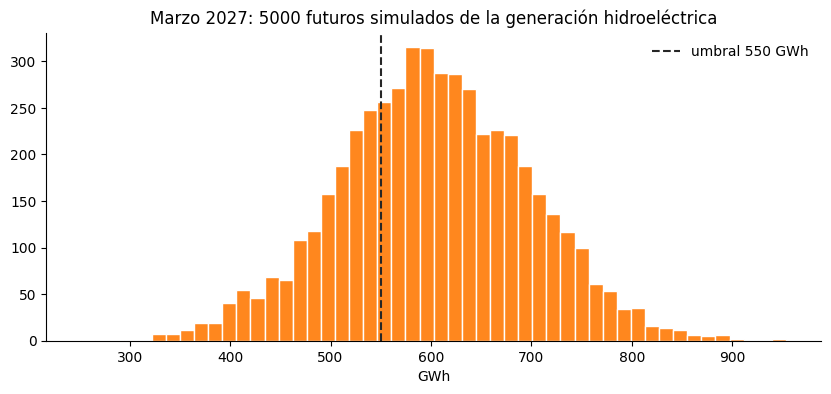

In [ ]:
IDX_MAR = list(FUTURO).index(pd.Timestamp("2027-03-01"))
mar = sims[IDX_MAR, :]
UMBRAL = 550
p_mc = float(np.mean(mar < UMBRAL))
ee = np.sqrt(p_mc * (1 - p_mc) / len(mar))
print(f"Marzo 2027 (modelo {MEJOR}): media simulada = {mar.mean():.0f} GWh | p10 = {np.percentile(mar,10):.0f} | p90 = {np.percentile(mar,90):.0f}")
print(f"P(hidro mar 2027 < {UMBRAL} GWh) = {p_mc:.3f}   (error estándar de Monte Carlo ± {ee:.3f})")

# Control: remuestreo de residuos dentro de la muestra (bootstrap) sobre el pronóstico puntual de marzo 2027
if MEJOR in ("Holt-Winters", "SARIMA"):
    if MEJOR == "Holt-Winters":
        ajuste = ExponentialSmoothing(hidro, trend=TENDENCIA_HW, seasonal="add", seasonal_periods=12).fit()
        resid = (hidro - ajuste.fittedvalues).dropna().values
    else:
        ajuste = SARIMAX(hidro, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
        resid = ajuste.resid[13:]
    # simplificación: el error de pronóstico a 9 pasos es mayor que el residual a 1 paso, por eso este control es más optimista
    boot = media[IDX_MAR] + rng.choice(resid, size=NSIM, replace=True)
    print(f"Control por remuestreo de residuos (error a 1 paso): P = {np.mean(boot < UMBRAL):.3f}")

plt.hist(mar, bins=50, color=NARANJA, edgecolor="white")
plt.axvline(UMBRAL, color=OSCURO, ls="--", label=f"umbral {UMBRAL} GWh"); plt.legend(frameon=False)
plt.title("Marzo 2027: 5000 futuros simulados de la generación hidroeléctrica"); plt.xlabel("GWh"); plt.show()

**(IV) Mensaje para quien planifica el sistema eléctrico.**

Con el modelo SARIMA(1,0,0) (0,1,1) 1, esperamos que la generación hidroeléctrica siga su patrón estacional: alta en el segundo semestre de 2026 (cerca de 800 a
870 GWh) y con su punto más bajo en la época seca, en marzo de 2027, con unos
602 GWh. Para ese mes el rango probable (80%) va de 484 a 725 GWh.
Estimamos una probabilidad de 29 % (+0.6 puntos de error de Monte Carlo) de que la hidro de marzo de 2027 quede por debajo de 550 GWh. Es casi una de cada tres posibilidades, no un escenario raro, y ocurriría justo en la época seca, cuando la demanda es alta y se necesita más respaldo térmico. Recomendamos tener disponible el respaldo térmico para febrero a abril de 2027, vigilar el nivel de los embalses desde diciembre y actualizar el pronóstico cada mes con datos
nuevos.
Nuestra confianza
es moderada. El patrón estacional es estable y SARIMA le ganó
al ingenuo estacional en las tres ventanas de validación (MASE promedio de 1.118
contra 1.456), pero solo hay 90 meses de datos, el rango es amplio (más de 240 GWh de ancho en marzo) y el modelo no conoce el clima futuro: un El Niño como el de 2023-2024, que llevó la hidro a cerca de 490 GWh, quedaría fuera de lo que puede anticipar. Conviene usar el rango y no el número puntual.

PARTE 2
-

### 2.1 Regularización
**(a)** Ridge y Lasso le agregan un castigo a la función de error cuando los coeficientes se hacen grandes. Ridge castiga con la suma de los cuadrados ($\lambda\sum\beta_j^2$) y Lasso con la suma de los valores absolutos ($\lambda\sum|\beta_j|$). Al final lo que pasa es que los coeficientes se "encogen" hacia cero. Eso ayuda con el sobreajuste porque el modelo ya no se puede acomodar tanto al ruido del entrenamiento, y si cambian un poco los datos el modelo no cambia tanto (baja la varianza).

**(b)** La diferencia más práctica es que Lasso puede dejar coeficientes exactamente en 0, entonces de paso elimina variables. Ridge solo los hace más pequeños pero no quita ninguna. Las dos meten un poco de sesgo para bajar varianza; Lasso sirve más si sospechamos que muchas variables no aportan nada, y Ridge cuando casi todas aportan algo o están correlacionadas entre sí.

**(c)** Tiene sentido si uno piensa que la regularización ayuda cuando hay sobreajuste, y ese modelo no estaba sobreajustando: tendencia más 11 meses son pocos parámetros para la cantidad de datos. Entonces al penalizar solo se metió sesgo (se achicó la tendencia y el efecto de cada mes) sin ganar nada en varianza, y por eso el RMSE salió peor que con mínimos cuadrados.

Lo de `TimeSeriesSplit` es porque en una serie de tiempo el orden importa. Un K-fold normal revuelve los meses y termina usando datos del futuro para predecir el pasado, y eso da un error más bajo de lo que realmente va a pasar. Con `TimeSeriesSplit` siempre se entrena con lo anterior y se prueba con lo que sigue, que es como se usaría el modelo en la vida real.

### 2.2 Cadena de Markov con datos reales
**(a)** La segunda fila dice que si un mes fue de hidro baja, hay un 71 % de probabilidad de que el siguiente también sea bajo y solo un 29 % de que suba a alto. O sea, los meses bajos tienden a venir seguidos. Si sacamos $1/0.29$ da como 3.4 meses en promedio, que es más o menos lo que dura la época seca.

**(b)** La distribución estacionaria es qué porcentaje del tiempo pasa la cadena en cada estado a largo plazo, sin importar en cuál arrancó.

$\pi P = \pi$ con $\pi_A + \pi_B = 1$

De la primera columna: $\pi_A = 0.83\pi_A + 0.29\pi_B$, entonces $0.17\pi_A = 0.29\pi_B$

Despejando con la suma igual a 1: $\pi_A = \dfrac{0.29}{0.46} \approx 0.63$ y $\pi_B \approx 0.37$

Entonces más o menos 63 % de los meses serían de hidro alta. Lo comparamos con los datos y en la serie el 61 % de los meses tienen 700 GWh o más, así que está bastante cerca.

**(c)** Creemos que no del todo. Primero, la cadena no sabe en qué mes estamos: estar en B en abril, cuando ya casi empiezan las lluvias, no es lo mismo que estar en B en diciembre, que apenas empieza la seca. Y segundo, con El Niño un año entero puede salir seco, entonces la probabilidad de salir de B ese año es menor que el 29 % promedio. El mes siguiente no depende solo del actual, también del año que se está viviendo. Se podría mejorar con una matriz por mes o metiendo El Niño como otro estado.

**(d)** PageRank es básicamente la distribución estacionaria de una cadena de Markov donde los estados son páginas y las transiciones son los links, y los modelos de lenguaje hacen algo parecido al predecir la siguiente palabra, solo que con mucho más contexto que solo la palabra anterior.

### 2.3 Leer código
**(a)** Es MCMC, porque cada valor nuevo depende del anterior (es una cadena), no son muestras independientes. Es el algoritmo de Metropolis. Está muestreando la posterior de $p$: con 18 éxitos en 50 y prior plano queda proporcional a $p^{18}(1-p)^{32}$, que es una Beta(19, 33). La media de esa Beta es $19/52 \approx 0.365$, entonces esperamos que imprima algo cerca de 0.365. No da exactamente 0.36 (que sería 18/50) porque el prior plano suma un éxito y un fracaso.

**(b)**
- `prop` es el valor que se propone: se toma el $p$ actual y se mueve un poquito al azar con una normal de desviación 0.1.
- La comparación con `rng.uniform()` decide si se acepta. Si la propuesta tiene más probabilidad posterior que el valor actual, se acepta siempre; si tiene menos, se acepta solo a veces (con probabilidad igual al cociente). Así la cadena también visita valores menos probables y no se queda pegada en el máximo. Si no se acepta, se repite el mismo $p$. Si la propuesta se sale de (0, 1), `log_post` da $-\infty$ y nunca se acepta.
- Las primeras 2000 se botan porque al inicio la cadena todavía depende de donde arrancó (0.5) y no ha llegado a la distribución que queremos (burn-in).

**(c)** En el 1.e(iii) podíamos simular directo del modelo, cada trayectoria es independiente de las otras y la probabilidad es simplemente contar cuántas quedan bajo 550. En este código no se puede muestrear directo de la posterior, entonces se arma una cadena que poco a poco converge a esa distribución, y por eso las muestras están correlacionadas y hay que descartar el inicio.

### 2.4 Leer resultados
**(a)** No tiene razón. El MASE divide el error del modelo entre el error que tiene el ingenuo estacional dentro del entrenamiento (repetir el valor del mismo mes del año anterior). Que dé más de 1 solo dice que el modelo, pronosticando hasta 12 meses hacia adelante, se equivoca más que ese ingenuo dentro de la muestra, y eso es bastante normal si la prueba agarra años raros. Lo que hay que ver es cómo le va contra el ingenuo en las mismas ventanas: 1.10 contra 1.40 quiere decir que el modelo se equivoca como un 21 % menos. A nosotros nos pasó igual, el SARIMA tiene MASE promedio de 1.118 pero le gana al ingenuo (1.456) en las tres ventanas.

**(b)** Zero-shot quiere decir que el modelo ya viene entrenado con un montón de series de otras cosas y pronostica una serie nueva sin volver a entrenarlo con esos datos. Es una ventaja cuando uno tiene muchas series o series cortas, por ejemplo si hubiera que pronosticar cada planta por separado o una planta nueva con pocos datos. No basta cuando lo que pasa depende de algo que el modelo no ve, como si viene El Niño o si entra una planta nueva al sistema, porque solo conoce la historia de la serie. En nuestro caso Chronos-2 quedó muy cerca del SARIMA (1.136 contra 1.118) sin entrenarse, pero en la ventana de 2024 falló igual que los demás (1.625) porque no tenía cómo saber que venían las lluvias de 2025.

**(c)** Que no se puede escoger un modelo con un solo año de prueba, porque puede ganar por suerte. Con varias ventanas se ve cómo le va en promedio y qué tan estable es. A nosotros nos pasó: con la prueba oficial Prophet era el mejor por mucho, pero con las tres ventanas quedó casi igual que el ingenuo.

PARTE 3
-
Ejercicios a mano (3.1 crecimiento exponencial, 3.2 métricas de error, 3.3 cadena de dos estados).

**3.1 Crecimiento exponencial**

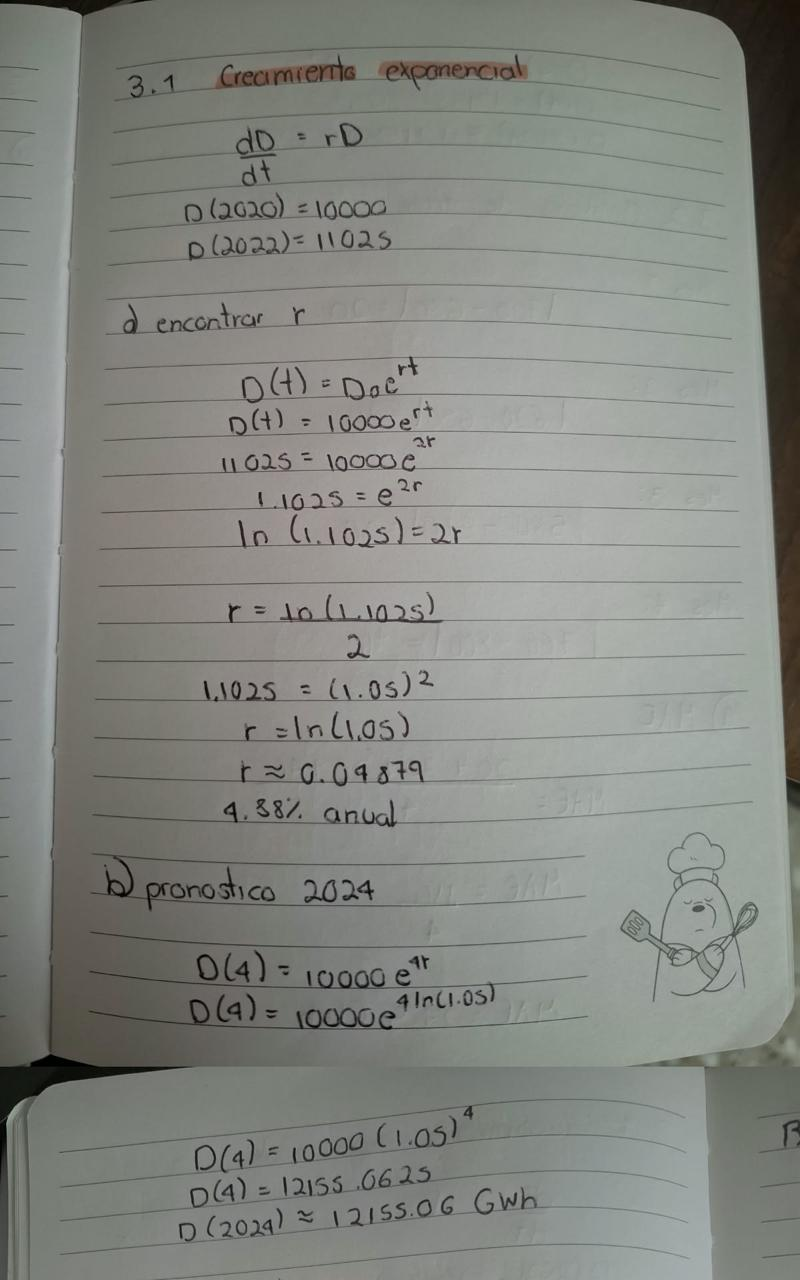

**3.2 Métricas de error**

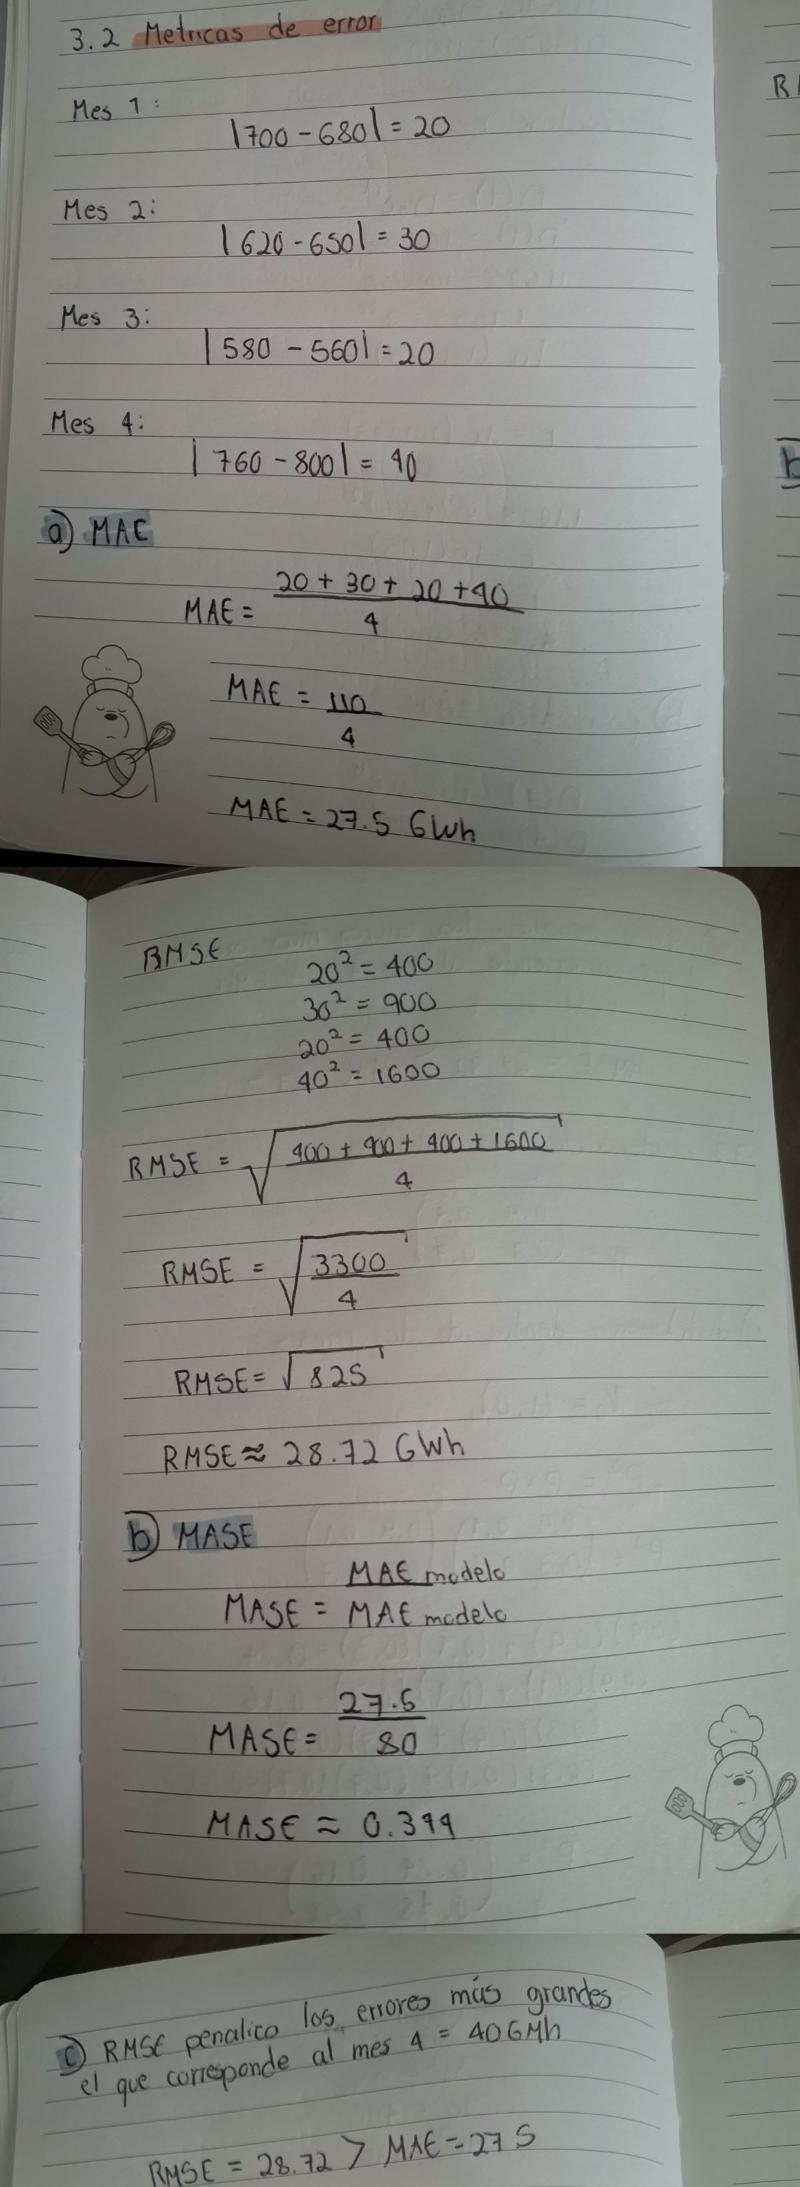

**3.3 Cadena de dos estados**

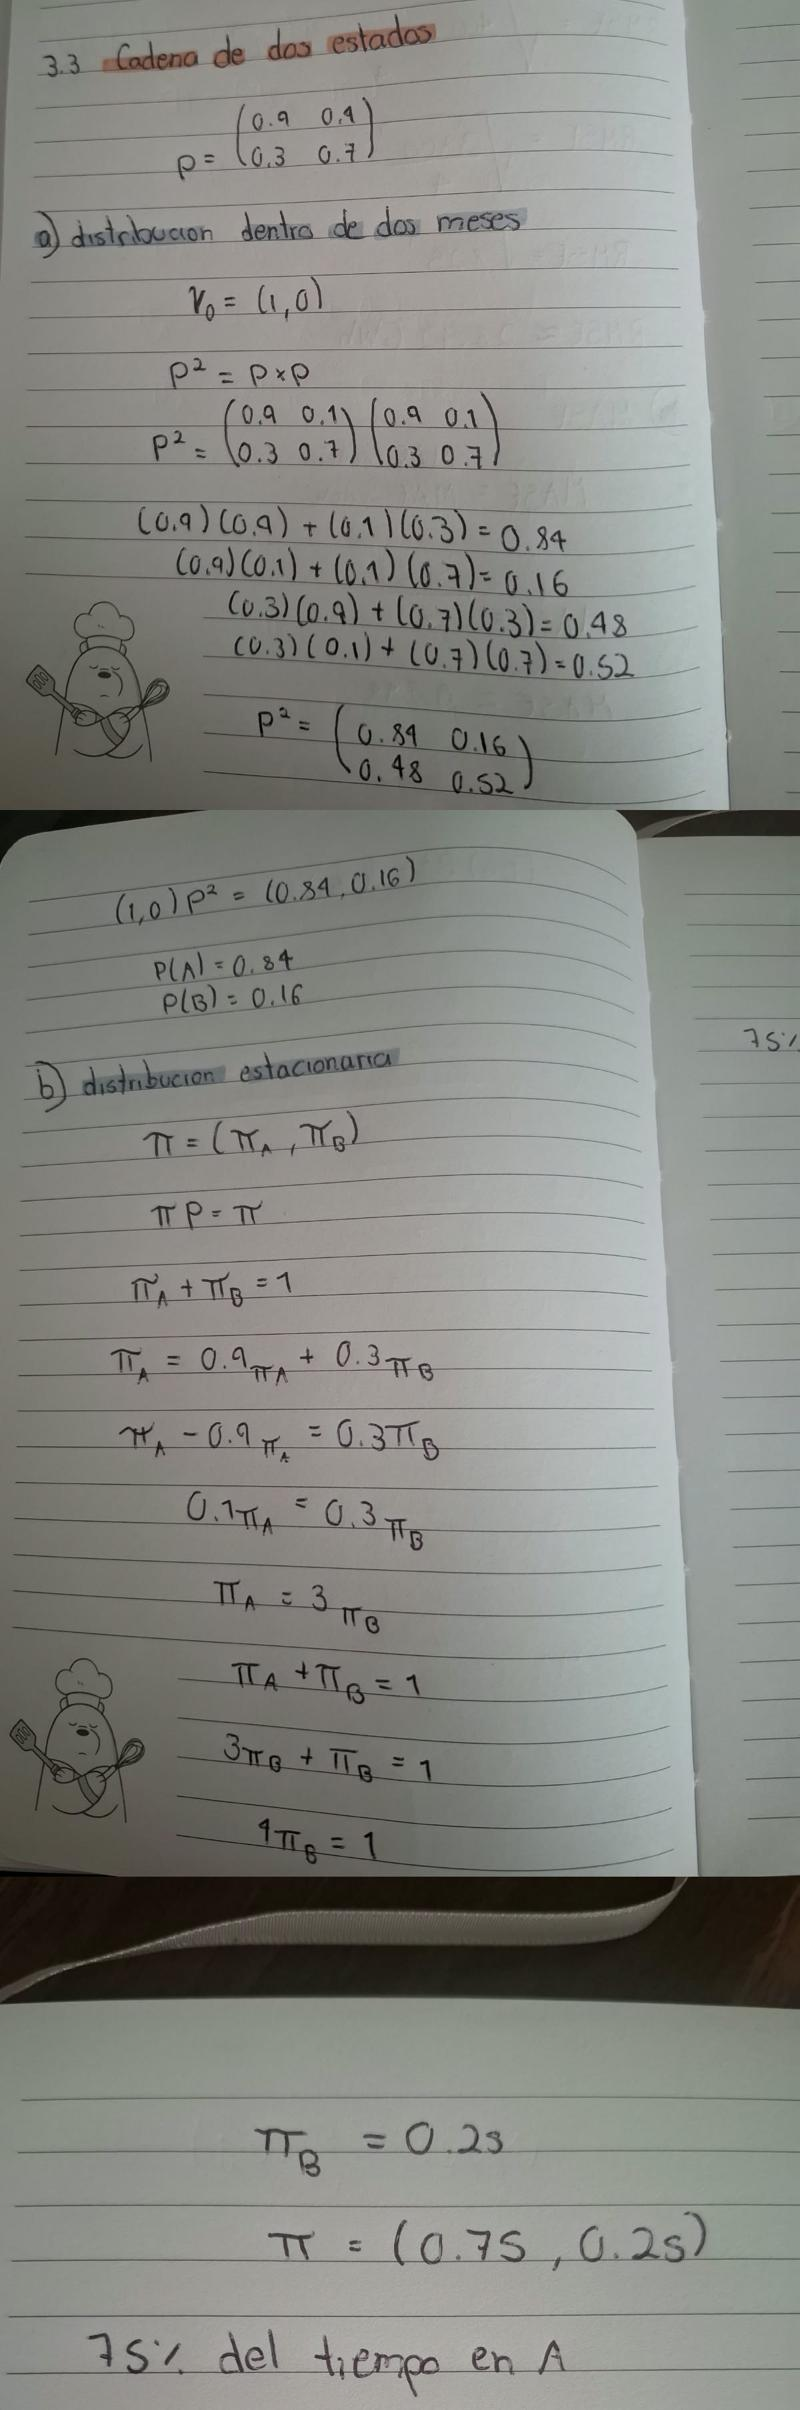

## Declaración de uso de inteligencia artificial

Usamos **Claude** (Anthropic) como apoyo en la parte 1 y 2, para la redacción y revisión de las respuestas conceptuales. Revisamos todas las respuestas y las podemos explicar. La parte 3 se hizo a mano.